# Experiment 2: high grades and tutoring (Hypothesis 2)

**Hypothesis 2:** If students have high grades in different courses, then they don't need tutoring in those same courses.

This notebook tests it straight from the school's data files:

1. **Load the data** and build one row per student per Math, English and Science course.
2. **Make fair pairs:** each tutored course is paired with an untutored course that started out alike.
3. **R6 – Experiment:** compare how often each side kept its grade, and apply the decision rule.
4. **R7 – Model building:** Naive Bayes models with and without "tutored", using 5-fold cross-validation.
5. **R8 – Validation:** test the chosen models on students they have never seen.
6. **Log everything to MLflow** and state the conclusion.



Courses that started with a C, D or F are a comparison group, with the outcome "reached a B or better" (keeping a grade means nothing for an F, which can't drop).

In [1]:
# Setup
import json
import re
import warnings
from pathlib import Path
import os
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss,
                             confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import KFold, train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

DATA_FOLDER = Path(".")          # folder with the data files, for example Path("cleaned_data")
OUTPUT_DIR = Path("h2_outputs")  # tables and the chart (also attached to the MLflow run)
OUTPUT_DIR.mkdir(exist_ok=True)
#os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"   # newer MLflow refuses an mlruns folder without this
os.environ["MLFLOW_TRACKING_USERNAME"] = "csc-4933-002-user01"
os.environ["MLFLOW_TRACKING_PASSWORD"] = "Eq8JCmHrANKvEpVb"
mlflow.set_tracking_uri("http://10.0.100.20:5000")   # the class MLflow server (http:// is required)

SEED = 42                # same pairs, splits and bootstrap samples on every run
N_FOLDS = 5              # 5-fold cross-validation
BOOTSTRAP_REPS = 1000    # resamples for the confidence intervals
PROGRAM_START = pd.Timestamp("2025-08-18")   # first day of tutoring sessions
TERM2_START = pd.Timestamp("2025-11-04")     # first day of Term 2
TERM3_START = pd.Timestamp("2026-02-18")     # first day of Term 3
TUTORED_SUBJECTS = ["Mathematics", "English Language Arts", "Science"]
LETTER_POINTS = {"A": 4.0, "B": 3.0, "C": 2.0, "D": 1.0, "F": 0.0}
HIGH_GRADES = ["A", "B"]         # a "high grade" is a Term 1 A or B in the course
B_OR_BETTER = 80                 # a Term 3 percentage of 80+ is a B or better
GPA_BAND_WIDTH = 0.5             # GPA bands used for matching and as model features
MEANINGFUL_BENEFIT = 5.0         # smallest benefit from tutoring (percentage points) that would matter
ALPHAS = (0.1, 0.5, 1.0, 2.0)    # Naive Bayes smoothing strengths tried in R7
ABSENCE_BANDS = ([-0.5, 0.5, 2.5, 5.5, 9.5, np.inf], ["0", "1-2", "3-5", "6-9", "10+"])
SUBGROUPS = {"high_start": "Started with an A or B", "not_high_start": "Started with a C, D or F"}
OUTCOMES = {"high_start": "kept its Term 1 grade or better", "not_high_start": "reached a B or better"}
GROUP_NAMES = {1: "Tutored from Term 2", 0: "Matched, not tutored"}
TUTORED_COLOR, UNTUTORED_COLOR, TEXT_COLOR = "#7a4ea0", "#0f8c74", "#52514e"   # color-blind-checked

In [2]:
# Helper functions
def find_file(name):
    """name.csv or name.csv.gz in DATA_FOLDER. If it isn't there, a renamed copy such as
    term_grades_2.csv or "term_grades (1).csv" is used instead."""
    for path in (DATA_FOLDER / f"{name}.csv", DATA_FOLDER / f"{name}.csv.gz"):
        if path.exists():
            return path
    pattern = re.compile(rf"^(?:\w+-)?{re.escape(name)}(?:_\d+| ?\(\d+\))?\.csv(?:\.gz)?$", re.IGNORECASE)
    matches = sorted(p for p in DATA_FOLDER.iterdir() if pattern.match(p.name))
    if not matches:
        raise FileNotFoundError(f"Can't find {name}.csv in {DATA_FOLDER} - check DATA_FOLDER.")
    return matches[0]


def gpa_band(gpa):
    """Band label such as '2.5-3.0' for each GPA, or 'missing'."""
    gpa = pd.to_numeric(gpa, errors="coerce")
    low = (np.floor(gpa / GPA_BAND_WIDTH + 1e-9) * GPA_BAND_WIDTH).fillna(-1)
    labels = [f"{lo:.1f}-{lo + GPA_BAND_WIDTH:.1f}" for lo in low]
    return pd.Series(np.where(gpa.between(0, 4), labels, "missing"), index=gpa.index)


def as_category(s):
    """Text category with blanks shown as 'Unknown'."""
    cleaned = s.astype("string").str.strip().fillna("Unknown")
    return cleaned.mask(cleaned.eq(""), "Unknown").astype(str)


def binary_metrics(y_true, prob):
    """Scores for predicted chances of meeting the outcome (a chance of 0.5+ counts as 'met')."""
    y_pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"roc_auc": float(roc_auc_score(y_true, prob)),
            "average_precision": float(average_precision_score(y_true, prob)),
            "accuracy": float(accuracy_score(y_true, y_pred)),
            "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
            "precision": float(precision_score(y_true, y_pred, zero_division=0)),
            "recall": float(recall_score(y_true, y_pred, zero_division=0)),
            "f1": float(f1_score(y_true, y_pred, zero_division=0)),
            "brier": float(brier_score_loss(y_true, prob)),   # mean squared gap between chance and result
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


def bootstrap_ci(y, prob, metric="roc_auc", reps=BOOTSTRAP_REPS, seed=SEED):
    """95% interval for a test score, by resampling the test courses."""
    rng = np.random.default_rng(seed)
    scores = []
    for _ in range(reps):
        i = rng.integers(0, len(y), size=len(y))
        if np.unique(y[i]).size < 2:
            continue
        if metric == "roc_auc":
            scores.append(roc_auc_score(y[i], prob[i]))
        elif metric == "f1":
            scores.append(f1_score(y[i], (prob[i] >= 0.5).astype(int), zero_division=0))
        else:
            scores.append(recall_score(y[i], (prob[i] >= 0.5).astype(int), zero_division=0))
    return tuple(map(float, np.percentile(scores, [2.5, 97.5])))


def paired_auc_delta_ci(y, new_p, base_p, reps=BOOTSTRAP_REPS):
    """AUC of one model minus another on the same test courses, with a 95% interval."""
    point = float(roc_auc_score(y, new_p) - roc_auc_score(y, base_p))
    rng = np.random.default_rng(SEED + 10)
    diffs = []
    for _ in range(reps):
        i = rng.integers(0, len(y), size=len(y))
        if np.unique(y[i]).size == 2:
            diffs.append(roc_auc_score(y[i], new_p[i]) - roc_auc_score(y[i], base_p[i]))
    low, high = map(float, np.percentile(diffs, [2.5, 97.5]))
    return {"auc_gain": point, "ci_low": low, "ci_high": high}


def ci_side(low, high):
    return "above zero" if low > 0 else "below zero" if high < 0 else "includes zero"


def log_model(model, X):
    """Save a fitted model to the active MLflow run (works with MLflow 2 and 3)."""
    with warnings.catch_warnings():
        # MLflow notes that the 0/1 predictions are whole numbers; that's expected here
        warnings.filterwarnings("ignore", message=".*Inferred schema contains integer column.*")
        try:
            mlflow.sklearn.log_model(model, name="model", input_example=X.head(5))
        except TypeError:   # MLflow 2.x calls this argument artifact_path
            mlflow.sklearn.log_model(model, artifact_path="model", input_example=X.head(5))

## Loading the data and build one row per course

Term 1 grades are letters (A–F); Terms 2 and 3 are percentages, turned into letters with 90/80/70/60 cutoffs.

In [3]:
paths = {name: find_file(name) for name in ["students", "term_grades", "courses", "tutoring_sessions"]}
for name, path in paths.items():
    print(f"{name:<18} <- {path.name}")

students = pd.read_csv(paths["students"], dtype={"student_id": str, "school_code": str})
grades = pd.read_csv(paths["term_grades"], dtype={"student_id": str, "course_code": str, "term_grade": str})
courses = pd.read_csv(paths["courses"], dtype={"course_code": str, "subject_area": str})
sessions = pd.read_csv(paths["tutoring_sessions"],   # .gz files are unzipped automatically
                       dtype={"student_id": str, "session_id": str, "subject_area": str, "attendance": str})
assert not students.student_id.duplicated().any(), "students.csv lists a student more than once"
grades, sessions = grades.drop_duplicates(), sessions.drop_duplicates()
print(f"\n{len(students):,} students, {len(grades):,} term grades, {len(sessions):,} tutoring sessions")

students           <- students.csv
term_grades        <- term_grades.csv
courses            <- courses.csv
tutoring_sessions  <- tutoring_sessions.csv

40,000 students, 720,000 term grades, 413,370 tutoring sessions


In [4]:
grades["term"] = pd.to_numeric(grades["term"], errors="coerce")
grades = grades.merge(courses[["course_code", "subject_area"]], on="course_code", how="left")
grades["subject_area"] = grades.subject_area.fillna("").astype(str).str.strip()
text = grades.term_grade.fillna("").astype(str).str.strip()
letters = text.str.upper().str.rstrip("+-")
is_term1 = grades.term.eq(1).to_numpy()
grades["letter"] = np.where(is_term1 & letters.isin(list(LETTER_POINTS)).to_numpy(), letters, None)
percent = pd.to_numeric(text, errors="coerce").to_numpy(dtype=float)
valid = (grades.term.isin([2, 3]).to_numpy() & np.isfinite(percent)
         & (percent >= 0) & (percent <= 100) & (percent % 1 == 0))
grades["percent"] = np.where(valid, percent, np.nan)
percent_points = np.select([valid & (percent >= 90), valid & (percent >= 80), valid & (percent >= 70),
                            valid & (percent >= 60), valid], [4.0, 3.0, 2.0, 1.0, 0.0], default=np.nan)
grades["points"] = np.where(is_term1, pd.Series(grades.letter).map(LETTER_POINTS).to_numpy(dtype=float),
                            percent_points)
grades["absences"] = pd.to_numeric(grades.absences, errors="coerce")
grades.loc[(grades.absences < 0) | (grades.absences % 1 != 0), "absences"] = np.nan

# Term 1 GPA: average of six valid Term 1 letter grades
t1 = grades[grades.term.eq(1)].groupby("student_id").agg(
    term1_gpa=("points", "mean"), n_valid=("points", "count"), n_courses=("course_code", "nunique"))
term1_gpa = t1.loc[(t1.n_valid == 6) & (t1.n_courses == 6), "term1_gpa"]

keys = ["student_id", "subject_area"]
core = grades[grades.subject_area.isin(TUTORED_SUBJECTS) & grades.term.isin([1, 2, 3])]
assert not core.duplicated(keys + ["term"]).any(), "a student has two courses in one subject in one term"
term1_rows = core[core.term.eq(1)][keys + ["course_code", "letter", "points", "absences"]].rename(
    columns={"letter": "term1_grade", "points": "term1_points", "absences": "term1_course_absences"})
term3_rows = core[core.term.eq(3)][keys + ["percent", "points"]].rename(
    columns={"percent": "term3_percent", "points": "term3_points"})
course_rows = term1_rows.merge(term3_rows, on=keys, validate="one_to_one")
course_rows = course_rows[course_rows.term1_grade.notna() & course_rows.term3_percent.notna()]
print(f"{len(course_rows):,} Math, English and Science courses with a Term 1 grade and a Term 3 grade")

120,000 Math, English and Science courses with a Term 1 grade and a Term 3 grade


In [5]:
sessions["session_date"] = pd.to_datetime(sessions.session_date, errors="coerce")
sessions["minutes"] = pd.to_numeric(sessions.minutes, errors="coerce")
sessions["subject_area"] = sessions.subject_area.fillna("").astype(str).str.strip()
attendance = sessions.attendance.fillna("").astype(str).str.strip().str.lower()
attended = sessions[(sessions.session_date >= PROGRAM_START) & attendance.eq("present") & sessions.minutes.eq(45)]
first = (attended.assign(before_t3=attended.session_date.lt(TERM3_START).astype(int))
         .groupby(keys, as_index=False)
         .agg(first_session=("session_date", "min"), sessions_before_t3=("before_t3", "sum")))
scheduled = sessions[keys].drop_duplicates().assign(scheduled=1)
course_rows = course_rows.merge(first, on=keys, how="left").merge(scheduled, on=keys, how="left")
fs = course_rows.first_session
course_rows["tutoring_status"] = np.select(
    [fs.lt(TERM2_START), fs.lt(TERM3_START), fs.notna(), course_rows.scheduled.eq(1)],
    ["first tutored in Term 1", "first tutored in Term 2", "first tutored in Term 3", "scheduled, never attended"],
    default="never scheduled")

student_cols = ["student_id", "school_code", "grade_level", "econ_disadvantaged", "english_learner",
                "iep", "bus_rider", "prior_year_gpa"]
course_rows = course_rows.merge(students[student_cols], on="student_id", validate="many_to_one")
course_rows = course_rows.merge(term1_gpa, left_on="student_id", right_index=True)
course_rows = course_rows[course_rows.school_code.notna()]

uses = {"first tutored in Term 2": "tutored group", "never scheduled": "pool of untutored courses",
        "first tutored in Term 1": "left out: Term 1 grade isn't from before tutoring",
        "first tutored in Term 3": "left out: tutoring started too late",
        "scheduled, never attended": "left out: fits neither group"}
status = course_rows.tutoring_status.value_counts().rename_axis("tutoring status").to_frame("courses")
status["used as"] = status.index.map(uses)
status

,courses,used as
tutoring status,,
never scheduled,105083,pool of untutored courses
first tutored in Term 1,10425,left out: Term 1 grade isn't from before tutoring
first tutored in Term 2,2982,tutored group
first tutored in Term 3,1438,left out: tutoring started too late
"scheduled, never attended",72,left out: fits neither group


##  Make fair pairs

Students aren't tutored at random: struggling students get referred. So comparing all tutored courses with all untutored ones would mostly show who got referred. The **hidden variables** are the starting grade and the student's overall academic strength: they affect both who gets tutored and how the course ends.

So each tutored course is paired with a randomly picked untutored course (seed 42) that has the same:
- school and subject,
- Term 1 letter grade in the course,
- Term 1 GPA band and prior-year GPA band (0.5-point bands; a missing prior-year GPA is its own band).

The balance check afterwards shows whether the two sides really are alike. A **standardized difference** below 0.1 in size is usually treated as well balanced.

In [6]:
eligible = course_rows[course_rows.tutoring_status.isin(["first tutored in Term 2", "never scheduled"])].copy()
eligible["tutored"] = eligible.tutoring_status.eq("first tutored in Term 2").astype(int)
eligible["sessions_before_t3"] = eligible.sessions_before_t3.fillna(0).astype(int)
eligible = eligible.sort_values(keys).reset_index(drop=True)
eligible["term1_gpa_band"] = gpa_band(eligible.term1_gpa)
eligible["prior_year_gpa_band"] = gpa_band(eligible.prior_year_gpa)

MATCH_ON = ["school_code", "subject_area", "term1_grade", "term1_gpa_band", "prior_year_gpa_band"]
pools = {key: group for key, group in eligible[eligible.tutored == 0].groupby(MATCH_ON)}
parts, next_pair = [], 1
for key, group in eligible[eligible.tutored == 1].groupby(MATCH_ON):
    pool = pools.get(key)
    n = 0 if pool is None else min(len(group), len(pool))
    if n == 0:
        continue
    pair_ids = np.arange(next_pair, next_pair + n)
    next_pair += n
    parts.append(group.sample(n=n, random_state=SEED).assign(pair_id=pair_ids))
    parts.append(pool.sample(n=n, random_state=SEED).assign(pair_id=pair_ids))
matched = (pd.concat(parts, ignore_index=True)
           .sort_values(["pair_id", "tutored"], ascending=[True, False]).reset_index(drop=True))

# Outcomes and model features
matched["start_group"] = np.where(matched.term1_grade.isin(HIGH_GRADES), "high_start", "not_high_start")
matched["kept_term1_grade"] = (matched.term3_points >= matched.term1_points).astype(int)
matched["b_or_better_term3"] = (matched.term3_percent >= B_OR_BETTER).astype(int)
matched["outcome"] = np.where(matched.start_group == "high_start", matched.kept_term1_grade, matched.b_or_better_term3)
matched["prior_year_gpa"] = pd.to_numeric(matched.prior_year_gpa, errors="coerce").where(lambda s: s.between(0, 4))
for column in ["school_code", "subject_area", "grade_level", "econ_disadvantaged", "english_learner", "iep", "bus_rider"]:
    matched[column] = as_category(matched[column])
matched["tutored_flag"] = np.where(matched.tutored == 1, "yes", "no")
matched["term1_absence_band"] = (pd.cut(matched.term1_course_absences, ABSENCE_BANDS[0], labels=ABSENCE_BANDS[1])
                                 .astype(str).replace("nan", "missing"))

n_tutored = int(eligible.tutored.sum())
pairs_by_group = matched.groupby("start_group").pair_id.nunique()
print(f"{matched.pair_id.nunique():,} matched pairs: {pairs_by_group['high_start']:,} started with an A or B, "
      f"{pairs_by_group['not_high_start']:,} with a C, D or F")
print(f"{n_tutored - matched.pair_id.nunique():,} of {n_tutored:,} tutored courses had no alike untutored course")

2,811 matched pairs: 488 started with an A or B, 2,323 with a C, D or F
171 of 2,982 tutored courses had no alike untutored course


In [7]:
BALANCE_VARIABLES = {
    "prior_year_gpa": "Prior-year GPA", "term1_gpa": "Term 1 GPA (all six courses)",
    "term1_points": "Term 1 grade in this course (points)", "term1_course_absences": "Term 1 absences in this course",
    "econ_disadvantaged": "Economically disadvantaged (share)", "english_learner": "English learner (share)",
    "iep": "IEP (share)", "bus_rider": "Bus rider (share)",
}
rows = []
for subgroup in SUBGROUPS:
    part = matched[matched.start_group == subgroup]
    for column, label in BALANCE_VARIABLES.items():
        values = (part[column].eq("Y").astype(float) if column in ["econ_disadvantaged", "english_learner", "iep", "bus_rider"]
                  else pd.to_numeric(part[column], errors="coerce"))
        t, u = values[part.tutored == 1], values[part.tutored == 0]
        spread = np.sqrt((t.var() + u.var()) / 2)
        rows.append({"subgroup": subgroup, "variable": label, "tutored_mean": t.mean(), "untutored_mean": u.mean(),
                     "std_difference": (t.mean() - u.mean()) / spread if spread > 0 else 0.0})
balance = pd.DataFrame(rows)
balance.to_csv(OUTPUT_DIR / "R6_h2_balance.csv", index=False)
print(f"Largest standardized difference: {balance.std_difference.abs().max():.2f}")
balance.round(3)

Largest standardized difference: 0.11


,subgroup,variable,tutored_mean,untutored_mean,std_difference
0,high_start,Prior-year GPA,2.830,2.859,-0.061
1,high_start,Term 1 GPA (all six courses),2.772,2.781,-0.013
2,high_start,Term 1 grade in this course (points),3.316,3.316,0.000
3,high_start,Term 1 absences in this course,3.031,3.033,-0.001
4,high_start,Economically disadvantaged (share),0.414,0.436,-0.046
5,high_start,English learner (share),0.053,0.031,0.112
6,high_start,IEP (share),0.100,0.111,-0.033
7,high_start,Bus rider (share),0.559,0.547,0.025
8,not_high_start,Prior-year GPA,2.040,2.077,-0.069
9,not_high_start,Term 1 GPA (all six courses),1.201,1.204,-0.003


## (R6): Compare the matched pairs

For each side: the share of courses that met the outcome.

The **difference** (tutored minus not tutored) gets a **paired bootstrap** interval: the pairs are resampled 1,000 times, the difference is recomputed each time, and the middle 95% is kept.

**Decision rule** (for courses that started with an A or B):
- **Supported:** the whole 95% interval for the benefit is below 5 points – any benefit is too small to matter.
- **Not supported:** the interval is above zero and a benefit of 5 points or more can't be ruled out.
- **Inconclusive:** anything else.

In [8]:
rows = []
for level, groups in [("start group", {"A or B": HIGH_GRADES, "C, D or F": ["C", "D", "F"]}),
                      ("term 1 grade", {g: [g] for g in LETTER_POINTS})]:
    for label, letters_in_group in groups.items():
        part = matched[matched.term1_grade.isin(letters_in_group)]
        for value, name in GROUP_NAMES.items():
            side = part[part.tutored == value]
            k, n = int(side.outcome.sum()), len(side)
            rows.append({"level": level, "term1_grade": label, "group": name, "n_courses": n, "n_outcome_met": k,
                         "outcome_rate": k / n, "mean_term3_points": side.term3_points.mean(),
                         "avg_sessions_before_t3": side.sessions_before_t3.mean()})
rates = pd.DataFrame(rows)
rates.to_csv(OUTPUT_DIR / "R6_h2_group_rates.csv", index=False)

# Easier-to-read view: one row per grade group
view = rates.pivot_table(index=["level", "term1_grade"], columns="group", values="outcome_rate", sort=False) * 100
view.insert(0, "pairs", rates[rates.group == GROUP_NAMES[1]].set_index(["level", "term1_grade"]).n_courses)
view["difference (points)"] = view[GROUP_NAMES[1]] - view[GROUP_NAMES[0]]
view["outcome"] = ["kept Term 1 grade" if g in ("A or B", "A", "B") else "reached B or better" for _, g in view.index]
view.round(1)

group                     pairs  Tutored from Term 2  Matched, not tutored  \
level        term1_grade                                                     
start group  A or B         488                 70.7                  48.4   
             C, D or F     2323                 24.7                  10.0   
term 1 grade A              154                 66.2                  44.2   
             B              334                 72.8                  50.3   
             C              630                 46.5                  24.4   
             D              740                 28.2                   8.5   
             F              953                  7.5                   1.6   

group                     difference (points)              outcome  
level        term1_grade                                            
start group  A or B                      22.3    kept Term 1 grade  
             C, D or F                   14.7  reached B or better  
term 1 grade A                           22.1    kept Term 1 grade  
             B                           22.5    kept Term 1 grade  
             C                           22.1  reached B or better  
             D                           19.7  reached B or better  
             F                            5.9  reached B or better

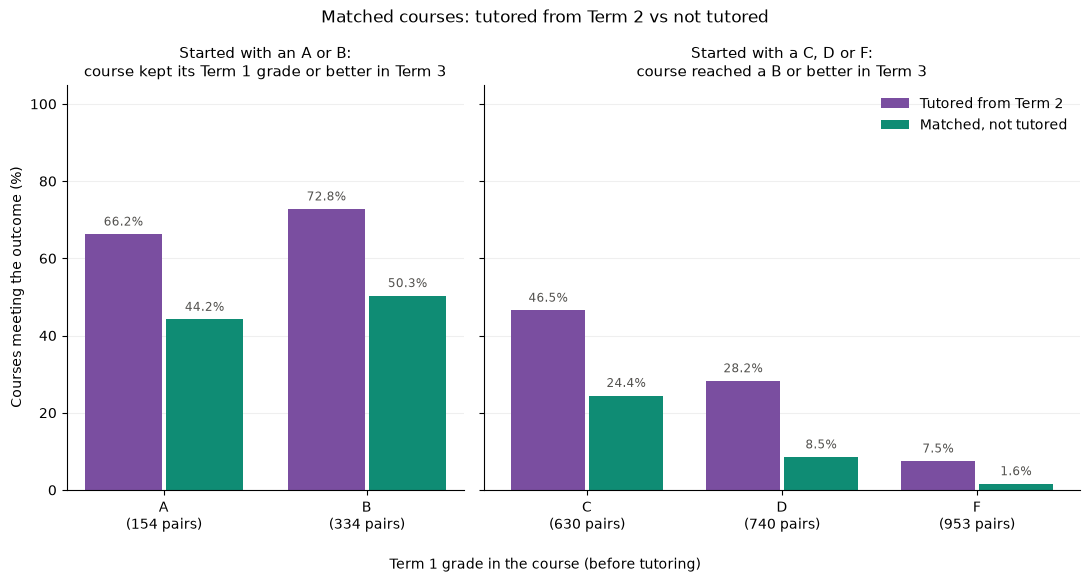

In [9]:
g = rates[rates.level == "term 1 grade"]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.8), sharey=True, gridspec_kw={"width_ratios": [2, 3]})
for ax, (subgroup, letters_in_panel) in zip(axes, [("high_start", ["A", "B"]), ("not_high_start", ["C", "D", "F"])]):
    x = np.arange(len(letters_in_panel))
    for offset, (value, name), color in zip((-0.2, 0.2), GROUP_NAMES.items(), (TUTORED_COLOR, UNTUTORED_COLOR)):
        part = g[g.group == name].set_index("term1_grade").reindex(letters_in_panel)
        rate = part.outcome_rate.to_numpy(float) * 100
        ax.bar(x + offset, rate, width=0.38, color=color, label=name)
        for xi, yi in zip(x + offset, rate):
            ax.text(xi, yi + 1.5, f"{yi:.1f}%", ha="center", va="bottom", fontsize=8.5, color=TEXT_COLOR)
    pairs = g[g.group == GROUP_NAMES[1]].set_index("term1_grade").reindex(letters_in_panel).n_courses
    ax.set_xticks(x, [f"{letter}\n({int(n):,} pairs)" for letter, n in zip(letters_in_panel, pairs)])
    ax.set_title(f"{SUBGROUPS[subgroup]}:\ncourse {OUTCOMES[subgroup]} in Term 3", fontsize=11)
    ax.set_ylim(0, 105)
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("Courses meeting the outcome (%)")
axes[1].legend(frameon=False, loc="upper right")
fig.supxlabel("Term 1 grade in the course (before tutoring)", fontsize=10)
fig.suptitle("Matched courses: tutored from Term 2 vs not tutored")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "h2_group_rates.png", dpi=160, facecolor="white")
plt.show()

In [10]:
def paired_difference(subgroup):
    part = matched[matched.start_group == subgroup]
    wide = part.pivot(index="pair_id", columns="tutored", values="outcome")
    tutored, untutored = wide[1].to_numpy(float), wide[0].to_numpy(float)
    d = tutored - untutored
    rng = np.random.default_rng(SEED)
    boot = d[rng.integers(0, len(d), size=(BOOTSTRAP_REPS, len(d)))].mean(axis=1)
    return {"subgroup": subgroup, "outcome": OUTCOMES[subgroup], "pairs": int(len(d)),
            "tutored_rate": float(tutored.mean()), "not_tutored_rate": float(untutored.mean()),
            "risk_difference": float(d.mean()),
            "95ci_low": float(np.percentile(boot, 2.5)), "95ci_high": float(np.percentile(boot, 97.5))}

contrasts = {subgroup: paired_difference(subgroup) for subgroup in SUBGROUPS}
(OUTPUT_DIR / "R6_h2_matched_differences.json").write_text(json.dumps(contrasts, indent=2))
for subgroup, c in contrasts.items():
    print(f"{SUBGROUPS[subgroup]} ({c['pairs']:,} pairs) - course {c['outcome']}: "
          f"tutored {c['tutored_rate']:.1%} vs not tutored {c['not_tutored_rate']:.1%}, "
          f"difference {c['risk_difference']*100:+.1f} points (95% CI {c['95ci_low']*100:+.1f} to {c['95ci_high']*100:+.1f})")

c = contrasts["high_start"]
low, high = c["95ci_low"] * 100, c["95ci_high"] * 100
if high < MEANINGFUL_BENEFIT:
    verdict = "SUPPORTED: any benefit of tutoring for high-start courses is below the threshold"
elif low > 0:
    verdict = "NOT SUPPORTED: tutoring clearly helped high-start courses keep their grade"
    if low >= MEANINGFUL_BENEFIT:
        verdict += f" (even the low end of the interval is above {MEANINGFUL_BENEFIT:g} points)"
else:
    verdict = "INCONCLUSIVE: no clear benefit, but a meaningful one can't be ruled out"
print(f"\nDecision rule (meaningful benefit = {MEANINGFUL_BENEFIT:g} points): Hypothesis 2 is {verdict}")

Started with an A or B (488 pairs) - course kept its Term 1 grade or better: tutored 70.7% vs not tutored 48.4%, difference +22.3 points (95% CI +16.8 to +28.5)
Started with a C, D or F (2,323 pairs) - course reached a B or better: tutored 24.7% vs not tutored 10.0%, difference +14.7 points (95% CI +12.7 to +16.6)

Decision rule (meaningful benefit = 5 points): Hypothesis 2 is NOT SUPPORTED: tutoring clearly helped high-start courses keep their grade (even the low end of the interval is above 5 points)


## (R7): Build Naive Bayes models

Separately for courses that started with an A or B and courses that started with a C, D or F, three **Naive Bayes** models predict whether a course meets its outcome:

**5-fold cross-validation:** first the students (not the course rows) are split 80/20, and the 20% are locked away for Step 5. The training students are split into 5 folds with `KFold(n_splits=5, shuffle=True, random_state=42)`. Each model trains on 4 folds and is scored (ROC AUC) on the 5th, five times over. Each model is tried with smoothing strengths alpha = 0.1, 0.5, 1 and 2 (smoothing stops a category seen in only a few courses from producing extreme evidence); the setting with the best average score is kept.

In [11]:
CONTROLS = ["term1_grade", "term1_gpa_band", "term1_absence_band", "prior_year_gpa_band", "school_code",
            "subject_area", "grade_level", "econ_disadvantaged", "english_learner", "iep", "bus_rider"]
FAMILIES = {"tutored_only": ["tutored_flag"],
            "controls_only": CONTROLS,
            "controls_plus_tutored": CONTROLS + ["tutored_flag"]}
# Every category of every feature (labels only, never outcomes), so a category missing from one
# training fold is still known to the model
CATEGORIES = {c: sorted(matched[c].astype(str).unique()) for c in CONTROLS + ["tutored_flag"]}


def build_model(family, alpha):
    columns = FAMILIES[family]
    encoder = ColumnTransformer([("codes", OrdinalEncoder(categories=[CATEGORIES[c] for c in columns]), columns)])
    return Pipeline([("encode", encoder),
                     ("nb", CategoricalNB(alpha=alpha, min_categories=[len(CATEGORIES[c]) for c in columns]))])


all_students = np.sort(matched.student_id.unique())
train_students, test_students = train_test_split(all_students, test_size=0.20, shuffle=True, random_state=SEED)
fold_of = {}
for fold_no, (_, valid_index) in enumerate(KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(train_students), start=1):
    for student in train_students[valid_index]:
        fold_of[student] = fold_no
assert not set(train_students) & set(test_students), "a student is in both training and holdout"

data = {}
for subgroup in SUBGROUPS:
    part = matched[matched.start_group == subgroup]
    train = part[part.student_id.isin(train_students)].reset_index(drop=True)
    test = part[part.student_id.isin(test_students)].reset_index(drop=True)
    fold_ids = train.student_id.map(fold_of).to_numpy()
    folds = [(np.flatnonzero(fold_ids != k), np.flatnonzero(fold_ids == k)) for k in range(1, N_FOLDS + 1)]
    data[subgroup] = (train, test, train.outcome.to_numpy(int), test.outcome.to_numpy(int), folds)
    print(f"{SUBGROUPS[subgroup]}: {len(train):,} training courses, {len(test):,} holdout courses")

Started with an A or B: 780 training courses, 196 holdout courses
Started with a C, D or F: 3,705 training courses, 941 holdout courses


In [12]:
cv_rows = []
for subgroup, (train, test, y_train, y_test, folds) in data.items():
    for family in FAMILIES:
        for alpha in ALPHAS:
            fold_aucs, fold_f1s, train_aucs = [], [], []
            for tr_i, va_i in folds:
                model = build_model(family, alpha).fit(train.iloc[tr_i], y_train[tr_i])
                prob_valid = model.predict_proba(train.iloc[va_i])[:, 1]
                fold_aucs.append(roc_auc_score(y_train[va_i], prob_valid))
                fold_f1s.append(f1_score(y_train[va_i], (prob_valid >= 0.5).astype(int), zero_division=0))
                train_aucs.append(roc_auc_score(y_train[tr_i], model.predict_proba(train.iloc[tr_i])[:, 1]))
            cv_rows.append({"subgroup": subgroup, "family": family, "alpha": alpha,
                            "cv_roc_auc_mean": np.mean(fold_aucs), "cv_roc_auc_sd": np.std(fold_aucs, ddof=1),
                            "cv_f1_mean": np.mean(fold_f1s), "cv_train_roc_auc_mean": np.mean(train_aucs),
                            "fold_aucs": fold_aucs})
cv_results = pd.DataFrame(cv_rows)
cv_results.drop(columns="fold_aucs").to_csv(OUTPUT_DIR / "R7_h2_cv_candidate_comparison.csv", index=False)

# The best smoothing setting for each model (ties go to the smaller alpha)
selected = (cv_results.sort_values(["subgroup", "family", "cv_roc_auc_mean", "alpha"],
                                   ascending=[True, True, False, True])
            .groupby(["subgroup", "family"], sort=False).head(1).set_index(["subgroup", "family"]))
selected[["alpha", "cv_roc_auc_mean", "cv_roc_auc_sd", "cv_f1_mean"]].round(3)

alpha  cv_roc_auc_mean  cv_roc_auc_sd  \
subgroup       family                                                         
high_start     controls_only            2.0            0.621          0.048   
               controls_plus_tutored    2.0            0.662          0.031   
               tutored_only             0.1            0.611          0.047   
not_high_start controls_only            2.0            0.798          0.026   
               controls_plus_tutored    2.0            0.817          0.025   
               tutored_only             0.1            0.627          0.035   

                                      cv_f1_mean  
subgroup       family                             
high_start     controls_only               0.664  
               controls_plus_tutored       0.696  
               tutored_only                0.634  
not_high_start controls_only               0.464  
               controls_plus_tutored       0.482  
               tutored_only                0.000

## (R8): Test on students the models have never seen

Each chosen model is retrained on all the training students and scored once on the holdout students. The key number is the **AUC gain**: the holdout ROC AUC of `controls_plus_tutored` minus `controls_only`, with a paired bootstrap 95% interval. If knowing who was tutored helps predict the outcome beyond background, the interval is above zero.

In [ ]:
final_rows, final_models, probabilities, gains = [], {}, {}, {}
for subgroup, (train, test, y_train, y_test, folds) in data.items():
    for family in FAMILIES:
        alpha = float(selected.loc[(subgroup, family), "alpha"])
        model = build_model(family, alpha).fit(train, y_train)
        test_p = model.predict_proba(test)[:, 1]
        test_scores = binary_metrics(y_test, test_p)
        cis = {m: bootstrap_ci(y_test, test_p, metric=m, seed=SEED + k) for k, m in enumerate(["roc_auc", "f1", "recall"])}
        final_models[(subgroup, family)] = model
        probabilities[(subgroup, family)] = test_p
        final_rows.append({"subgroup": subgroup, "family": family, "alpha": alpha,
                           "test_roc_auc": test_scores["roc_auc"], "auc_95ci": f"{cis['roc_auc'][0]:.3f}-{cis['roc_auc'][1]:.3f}",
                           "test_accuracy": test_scores["accuracy"], "test_f1": test_scores["f1"],
                           "test_recall": test_scores["recall"], "test_precision": test_scores["precision"],
                           "test_brier": test_scores["brier"],
                           "train_roc_auc": roc_auc_score(y_train, model.predict_proba(train)[:, 1]),
                           **{f"test_{k}": v for k, v in test_scores.items() if k in ("tp", "fp", "fn", "tn")}})
    gains[subgroup] = paired_auc_delta_ci(y_test, probabilities[(subgroup, "controls_plus_tutored")],
                                          probabilities[(subgroup, "controls_only")])
holdout = pd.DataFrame(final_rows)
holdout.to_csv(OUTPUT_DIR / "R8_h2_holdout_results.csv", index=False)
(OUTPUT_DIR / "R8_h2_auc_gain.json").write_text(json.dumps(gains, indent=2))
for subgroup, gain in gains.items():
    print(f"{SUBGROUPS[subgroup]}: AUC gain from adding 'tutored' {gain['auc_gain']:+.3f} "
          f"(95% CI {gain['ci_low']:+.3f} to {gain['ci_high']:+.3f}) - {ci_side(gain['ci_low'], gain['ci_high'])}")
holdout.round(3)

In [ ]:
# Likelihood ratio = how many times more common a category is among training courses that kept their grade than among those that dropped
# (above 1 pushes a prediction toward "kept"). Only categories seen in 30+ training courses are shown.
model = final_models[("high_start", "controls_plus_tutored")]
nb = model.named_steps["nb"]
rows = []
for column, log_probs, counts in zip(FAMILIES["controls_plus_tutored"], nb.feature_log_prob_, nb.category_count_):
    for code_, category in enumerate(CATEGORIES[column]):
        log_ratio = log_probs[1, code_] - log_probs[0, code_]
        rows.append({"feature": column, "category": category, "training_courses": int(counts[:, code_].sum()),
                     "likelihood_ratio": float(np.exp(log_ratio)), "strength": abs(log_ratio)})
evidence = pd.DataFrame(rows)
evidence.drop(columns="strength").to_csv(OUTPUT_DIR / "R7_h2_high_start_nb_evidence.csv", index=False)
shown = evidence[evidence.training_courses >= 30]
pd.concat([shown[shown.feature == "tutored_flag"].sort_values("category", ascending=False),
           shown[shown.feature != "tutored_flag"].nlargest(8, "strength")]).drop(columns="strength").round(2)

,feature,category,training_courses,likelihood_ratio
69,tutored_flag,yes,388,1.61
68,tutored_flag,no,392,0.64
26,prior_year_gpa_band,3.5-4.0,52,5.16
23,prior_year_gpa_band,2.0-2.5,167,0.50
9,term1_gpa_band,2.0-2.5,165,0.52
12,term1_gpa_band,3.5-4.0,104,1.91
29,school_code,417002,50,0.65
8,term1_gpa_band,1.5-2.0,79,0.72
34,school_code,417026,47,1.38
25,prior_year_gpa_band,3.0-3.5,162,1.37


In [ ]:
from sklearn.metrics import brier_score_loss, roc_auc_score

SLIDE_ROWS = {"controls_only": "Background (11 pre-tutoring features)",
              "controls_plus_tutored": "  + tutored",
              "tutored_only": "Tutored only"}
slide_rows = []
for subgroup in SUBGROUPS:
    y_test = data[subgroup][3]   # holdout outcomes
    for family, label in SLIDE_ROWS.items():
        prob = probabilities[(subgroup, family)]   # holdout predictions from Step 5a
        cv = selected.loc[(subgroup, family)]      # 5-fold CV results from Step 4b
        slide_rows.append({"start group": SUBGROUPS[subgroup], "Naive Bayes features": label,
                           "Test AUC": f"{roc_auc_score(y_test, prob):.3f}",
                           "5-fold CV": f"{cv.cv_roc_auc_mean:.3f} ± {cv.cv_roc_auc_sd:.3f}",
                           "Brier": f"{brier_score_loss(y_test, prob):.3f}"})
slide_table = pd.DataFrame(slide_rows)
slide_table.to_csv(OUTPUT_DIR / "R8_h2_slide_table.csv", index=False, encoding="utf-8-sig")  # opens cleanly in Excel
slide_table

## Log the experiment to MLflow

One parent run holds the plan, the matched results and the tables and chart. Under it is a run for every model and smoothing setting (with its 5 fold scores), and a run for each final model (with its holdout scores and the saved model).

In [ ]:
DESIGN = f"""**Hypothesis 2:** If students have high grades in different courses, then they don't need tutoring in those same courses.

**Unit:** one student's Math, English or Science course. **High grade:** Term 1 A or B. **Tutored:** first attended a session in that subject in Term 2.

**Fair comparison:** pairs matched on school, subject, Term 1 grade, Term 1 GPA band and prior-year GPA band.

**Outcome:** the course kept its Term 1 grade or better in Term 3. **Decision rule:** supported only if the whole 95% interval for the benefit is below {MEANINGFUL_BENEFIT:g} points.

**Model:** Naive Bayes (CategoricalNB) with and without "tutored"; {N_FOLDS}-fold KFold over students on 80%, holdout test on 20%."""

mlflow.set_experiment("Experiment 2 - high grades and tutoring (Naive Bayes)")
with mlflow.start_run(run_name="Hypothesis 2"):
    mlflow.set_tag("mlflow.note.content", DESIGN)   # shows as the run's description
    mlflow.set_tag("verdict", verdict)
    mlflow.log_params({"seed": SEED, "n_folds": N_FOLDS, "meaningful_benefit_points": MEANINGFUL_BENEFIT,
                       "gpa_band_width": GPA_BAND_WIDTH, "matched_pairs": int(matched.pair_id.nunique()),
                       "match_on": ", ".join(MATCH_ON)})
    for subgroup, c in contrasts.items():
        mlflow.log_metrics({f"{subgroup}_tutored_rate": c["tutored_rate"], f"{subgroup}_not_tutored_rate": c["not_tutored_rate"],
                            f"{subgroup}_difference": c["risk_difference"],
                            f"{subgroup}_difference_ci_low": c["95ci_low"], f"{subgroup}_difference_ci_high": c["95ci_high"],
                            f"{subgroup}_auc_gain": gains[subgroup]["auc_gain"],
                            f"{subgroup}_auc_gain_ci_low": gains[subgroup]["ci_low"],
                            f"{subgroup}_auc_gain_ci_high": gains[subgroup]["ci_high"]})
    mlflow.log_metric("max_abs_std_difference", float(balance.std_difference.abs().max()))
    for f in sorted(OUTPUT_DIR.iterdir()):
        mlflow.log_artifact(str(f))

    for row in cv_results.itertuples():
        with mlflow.start_run(run_name=f"{row.subgroup} / {row.family} / alpha {row.alpha:g}", nested=True):
            mlflow.log_params({"model": "CategoricalNB", "subgroup": row.subgroup, "feature_family": row.family,
                               "alpha": row.alpha, "features": ", ".join(FAMILIES[row.family]),
                               "outcome": OUTCOMES[row.subgroup], "cv": "KFold(5, shuffle, 42) over students"})
            mlflow.log_metrics({"cv_roc_auc_mean": row.cv_roc_auc_mean, "cv_roc_auc_sd": row.cv_roc_auc_sd,
                                "cv_f1_mean": row.cv_f1_mean, "cv_train_roc_auc_mean": row.cv_train_roc_auc_mean})
            for step, value in enumerate(row.fold_aucs, start=1):
                mlflow.log_metric("fold_roc_auc", value, step=step)

    for row in holdout.itertuples():
        cv = selected.loc[(row.subgroup, row.family)]
        with mlflow.start_run(run_name=f"FINAL {row.subgroup} / {row.family}", nested=True):
            mlflow.log_params({"model": "CategoricalNB", "subgroup": row.subgroup, "feature_family": row.family,
                               "alpha": row.alpha, "outcome": OUTCOMES[row.subgroup]})
            mlflow.log_metrics({"test_roc_auc": row.test_roc_auc, "test_accuracy": row.test_accuracy,
                                "test_f1": row.test_f1, "test_recall": row.test_recall,
                                "test_precision": row.test_precision, "test_brier": row.test_brier,
                                "cv_roc_auc_mean": float(cv.cv_roc_auc_mean), "cv_roc_auc_sd": float(cv.cv_roc_auc_sd),
                                "train_roc_auc": row.train_roc_auc})
            train = data[row.subgroup][0]
            log_model(final_models[(row.subgroup, row.family)], train[FAMILIES[row.family]])
print("Experiment 2 logged to MLflow")

## Conclusion

In [ ]:
hi, lo = contrasts["high_start"], contrasts["not_high_start"]
print(f"Hypothesis 2 is {verdict}.\n")
print(f"R6 - matched comparison ({hi['pairs']:,} pairs that started with an A or B):")
print(f"  {hi['tutored_rate']:.1%} of tutored courses kept their Term 1 grade, vs {hi['not_tutored_rate']:.1%} of "
      f"their matches: {hi['risk_difference']*100:+.1f} points (95% CI {hi['95ci_low']*100:+.1f} to {hi['95ci_high']*100:+.1f})")
print(f"  comparison - started with a C, D or F: {lo['tutored_rate']:.1%} vs {lo['not_tutored_rate']:.1%} reached a B or better")
g = gains["high_start"]
model_reading = {"above zero": "agrees: knowing who was tutored improves predictions",
                 "below zero": "disagrees: adding tutored made predictions worse",
                 "includes zero": "is inconclusive (its interval includes zero)"}[ci_side(g["ci_low"], g["ci_high"])]
print(f"\nR8 - Naive Bayes on unseen students (A or B courses): AUC gain {g['auc_gain']:+.3f} "
      f"(95% CI {g['ci_low']:+.3f} to {g['ci_high']:+.3f}), so the model test {model_reading}")
print("\nLimits: this is a matched observational comparison, not a randomized experiment. Referral reasons and")
print("motivation aren't recorded; if students who attend tutoring are more motivated, tutoring will look more")
print("helpful than it is. The results describe students who began tutoring in Term 2.")

Hypothesis 2 is NOT SUPPORTED: tutoring clearly helped high-start courses keep their grade (even the low end of the interval is above 5 points).

R6 - matched comparison (488 pairs that started with an A or B):
  70.7% of tutored courses kept their Term 1 grade, vs 48.4% of their matches: +22.3 points (95% CI +16.8 to +28.5)
  comparison - started with a C, D or F: 24.7% vs 10.0% reached a B or better

R8 - Naive Bayes on unseen students (A or B courses): AUC gain +0.063 (95% CI +0.030 to +0.100), so the model test agrees: knowing who was tutored improves predictions

Limits: this is a matched observational comparison, not a randomized experiment. Referral reasons and
motivation aren't recorded; if students who attend tutoring are more motivated, tutoring will look more
helpful than it is. The results describe students who began tutoring in Term 2.
